## Machine Learning Notebook Week-4

### Table of Contents

##### 1. Unsupervised Learning
##### 2. Clustering (K-Means / Heirarchichal / DBSCAN)
##### 3. Clsuter Evaluation Metrics (Elbow Plot / Dendrogram / Silhouette Score)
##### 4. Dimensionality Reduction Techniques
##### 5. Principal Component Analysis
##### 6. Association Rules
##### 7. Recommendation Engines

### Unsupervised learning

Unsupervised Learning is a type of machine learning where the model is trained on an unlabeled dataset. The system tries to identify hidden structures or patterns in the data without predefined output labels, often through techniques like clustering or dimensionality reduction.

In short in supervised learning we dont have Target Varible.

##### Clsutering

Clustering is an unsupervised learning technique used to group similar data points into clusters based on their characteristics or patterns — without using any predefined labels.
The goal is to ensure that data points in the same cluster are more similar to each other than to those in other clusters.

In simple words:
Clustering means grouping similar things together automatically based on their features.

Examples:

Grouping customers with similar buying behavior.

Organizing news articles by topic.

####  Data Definition (Customer finance data)

Here's a brief version of what you'll find in the data

**Cust_Number**: Unique customer identification number

**Yearly_Income**: Annual income of the customer

**Age**: Age of the customer

**Cust_Spend_Score**: Spending score of the customer

**Sex**: Gender of the customer (0 = male, 1 = female)

##### Load the Data

In [ ]:
import pandas as pd

In [ ]:
import pandas as pd
df=pd.read_csv('customer.csv')
df.head()


,Cust_Number,Yearly_Income,Age,Cust_Spend_Score,Sex
0,CUSTID1,15000,18,44,0
1,CUSTID2,15000,18,79,0
2,CUSTID3,16000,23,8,1
3,CUSTID4,16000,25,79,1
4,CUSTID5,17000,32,41,1


##### Scale the Data

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
df[['Yearly_Income','Cust_Spend_Score']]=scaler.fit_transform(df[['Yearly_Income','Cust_Spend_Score']])
df.head()

,Cust_Number,Yearly_Income,Age,Cust_Spend_Score,Sex
0,CUSTID1,-1.738999,18,-0.284181,0
1,CUSTID2,-1.738999,18,1.063563,0
2,CUSTID3,-1.700830,23,-1.670433,1
3,CUSTID4,-1.700830,25,1.063563,1
4,CUSTID5,-1.662660,32,-0.399702,1


In [ ]:
scaled_cluster=df[['Yearly_Income','Cust_Spend_Score']]
scaled_cluster.head()

,Yearly_Income,Cust_Spend_Score
0,-1.738999,-0.284181
1,-1.738999,1.063563
2,-1.700830,-1.670433
3,-1.700830,1.063563
4,-1.662660,-0.399702


#### K- Means Clsutering

Definition:
K-Means is a centroid-based clustering algorithm that divides the data into K distinct clusters.
It works by assigning each data point to the nearest cluster center (centroid) and then updating the centroids until they stabilize.

In simple words:
K-Means groups data into K clusters by finding the best center points (means) for each cluster.

##### K-Means Model

In [ ]:
from sklearn.cluster import KMeans
model=KMeans(n_clusters=5)
model.fit(scaled_cluster)

KMeans(n_clusters=5)

In [ ]:
scaled_cluster['5_clusters']=model.labels_
scaled_cluster.head()

/tmp/ipykernel_1943/2272767040.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  scaled_cluster['5_clusters']=model.labels_


,Yearly_Income,Cust_Spend_Score,5_clusters
0,-1.738999,-0.284181,3
1,-1.738999,1.063563,1
2,-1.700830,-1.670433,3
3,-1.700830,1.063563,1
4,-1.662660,-0.399702,3


In [ ]:
scaled_cluster['cluster_label']=model.labels_
scaled_cluster.head()

/tmp/ipykernel_1943/1354829820.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  scaled_cluster['cluster_label']=model.labels_


,Yearly_Income,Cust_Spend_Score,5_clusters,cluster_label
0,-1.738999,-0.284181,3,3
1,-1.738999,1.063563,1,1
2,-1.700830,-1.670433,3,3
3,-1.700830,1.063563,1,1
4,-1.662660,-0.399702,3,3


<Axes: xlabel='Yearly_Income', ylabel='Cust_Spend_Score'>

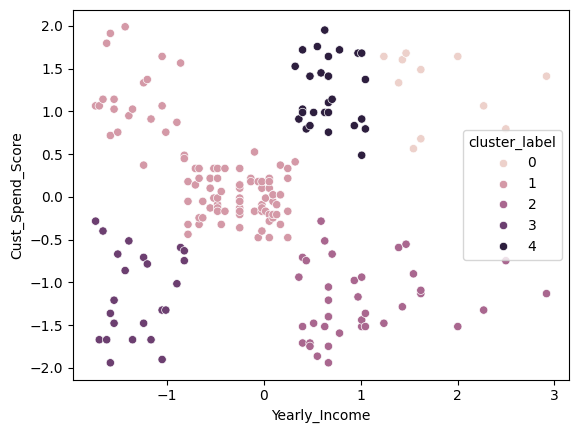

In [ ]:
import seaborn as sns
sns.scatterplot(data=scaled_cluster,x='Yearly_Income',y='Cust_Spend_Score',hue='cluster_label')

In [ ]:
scaled_cluster.drop(columns='cluster_label',inplace=True)
scaled_cluster.head()

/tmp/ipykernel_1943/634481724.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  scaled_cluster.drop(columns='cluster_label',inplace=True)


,Yearly_Income,Cust_Spend_Score,5_clusters
0,-1.738999,-0.284181,3
1,-1.738999,1.063563,1
2,-1.700830,-1.670433,3
3,-1.700830,1.063563,1
4,-1.662660,-0.399702,3


##### Optimal K Value Using Elbow Plot

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
wcss=[]
for i in range(1,11):
  model=KMeans(n_clusters=i)
  model.fit(scaled_cluster)
  wcss.append(model.inertia_)

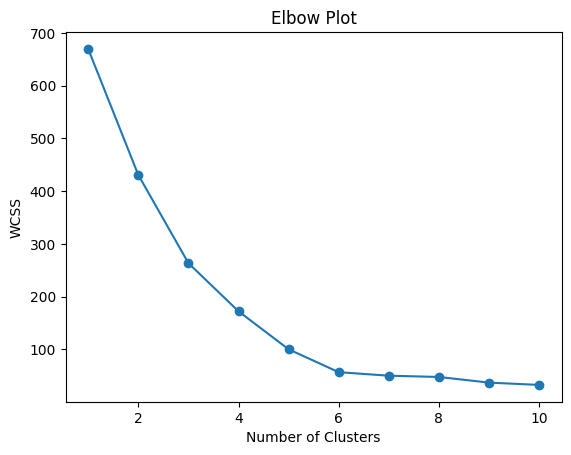

In [ ]:
import matplotlib.pyplot as plt
plt.plot(range(1,11),wcss,marker='o')
plt.title('Elbow Plot')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.show()

##### Optimal K Value Using Silhouette Score

The Silhouette score can also be used to identify the optimal number of clusters. We plot the Silhouette score for different values of K. The `K` with the highest Silhouette score represents the optimal value for the number of clusters (K).

Each bar in the silhouette plot represents one sample’s silhouette coefficient, which ranges from –1 to +1.

+1 → Perfectly matched to its cluster

0 → On the border between clusters

–1 → Possibly assigned to the wrong cluster

The average silhouette score (red dashed line) indicates the overall clustering quality.

In [ ]:
!pip install yellowbrick

In [ ]:
from sklearn.metrics import silhouette_score
from yellowbrick.cluster import SilhouetteVisualizer

In [ ]:
scaled_cluster.head()

,Yearly_Income,Cust_Spend_Score,5_clusters
0,-1.738999,-0.284181,3
1,-1.738999,1.063563,1
2,-1.700830,-1.670433,3
3,-1.700830,1.063563,1
4,-1.662660,-0.399702,3


In [ ]:
silhouette_score(scaled_cluster.drop(columns='5_clusters'),scaled_cluster['5_clusters'])

np.float64(0.45683521105375874)

In [ ]:
#this is the over all silhoutte score of the model.

In [ ]:
#lets build silhouette visualizer  in order to

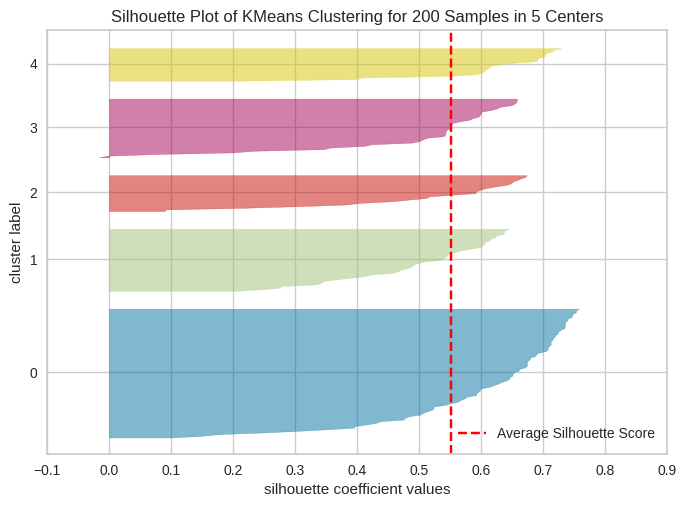

<Axes: title={'center': 'Silhouette Plot of KMeans Clustering for 200 Samples in 5 Centers'}, xlabel='silhouette coefficient values', ylabel='cluster label'>

In [ ]:
model=KMeans(n_clusters=5,random_state=100)
visualizer=SilhouetteVisualizer(model,colors='yellowbrick')
visualizer.fit(scaled_cluster.drop(columns='5_clusters'))
visualizer.show()

###### Build the KMeans Model with optimal k value

In [ ]:
#5 clusers

In [ ]:
scaled_cluster.head()

,Yearly_Income,Cust_Spend_Score,5_clusters
0,-1.738999,-0.284181,3
1,-1.738999,1.063563,4
2,-1.700830,-1.670433,3
3,-1.700830,1.063563,4
4,-1.662660,-0.399702,3


###### Cluster Evaluation

In [ ]:
final_clusters_df=pd.concat([df[['Cust_Number','Yearly_Income','Cust_Spend_Score']],scaled_cluster['5_clusters']],axis=1)

In [ ]:
final_clusters_df.head()

,Cust_Number,Yearly_Income,Cust_Spend_Score,5_clusters
0,CUSTID1,-1.738999,-0.284181,3
1,CUSTID2,-1.738999,1.063563,4
2,CUSTID3,-1.700830,-1.670433,3
3,CUSTID4,-1.700830,1.063563,4
4,CUSTID5,-1.662660,-0.399702,3


In [ ]:
cluster_1=final_clusters_df[final_clusters_df['5_clusters']==0]
cluster_2=final_clusters_df[final_clusters_df['5_clusters']==1]
cluster_3=final_clusters_df[final_clusters_df['5_clusters']==2]
cluster_4=final_clusters_df[final_clusters_df['5_clusters']==3]
cluster_5=final_clusters_df[final_clusters_df['5_clusters']==4]

In [ ]:
cluster_1.describe()

,Yearly_Income,Cust_Spend_Score,5_clusters
count,10.000000,10.000000,10.0
mean,1.875646,-1.027366,0.0
std,0.525529,0.321174,0.0
min,1.390894,-1.516405,0.0
25%,1.486318,-1.246856,0.0
50%,1.619911,-1.112081,0.0
75%,2.201994,-0.784772,0.0
max,2.917671,-0.553730,0.0


##### Hierarchical Clustering

Hierarchical Clustering is an unsupervised learning technique that groups data into a hierarchy or tree-like structure of clusters.
It either merges smaller clusters into larger ones (agglomerative approach) or divides a large cluster into smaller ones (divisive approach) until all data points are organized in a hierarchy.

In simple words: Hierarchical Clustering builds a tree of clusters, showing how data points are grouped together step by step.

###### Agglomerative Clustering

Agglomerative Clustering is the most common type of hierarchical clustering.
It starts by treating each data point as a single cluster and then repeatedly merges the two closest clusters until all points belong to one big cluster or a desired number of clusters is formed.

In simple words:
Agglomerative Clustering starts with individual points and keeps joining the nearest pairs of clusters step by step.

In [ ]:
import pandas as pd

###### Agglomarative Model

In [ ]:
from sklearn.cluster import AgglomerativeClustering
agg_model=AgglomerativeClustering(n_clusters=5,linkage='ward')
agg_model.fit(scaled_cluster)
scaled_cluster['agg_cluster']=agg_model.labels_
scaled_cluster.head()

,Yearly_Income,Cust_Spend_Score,5_clusters,agg_cluster
0,-1.738999,-0.284181,3,1
1,-1.738999,1.063563,1,0
2,-1.700830,-1.670433,3,1
3,-1.700830,1.063563,1,0
4,-1.662660,-0.399702,3,1


In [ ]:
scaled_cluster.drop(columns=['5_clusters','agg_cluster'],inplace=True)
scaled_cluster.head()

,Yearly_Income,Cust_Spend_Score
0,-1.738999,-0.284181
1,-1.738999,1.063563
2,-1.700830,-1.670433
3,-1.700830,1.063563
4,-1.662660,-0.399702


###### Cluster Evaluation

In [ ]:
## dendrogram

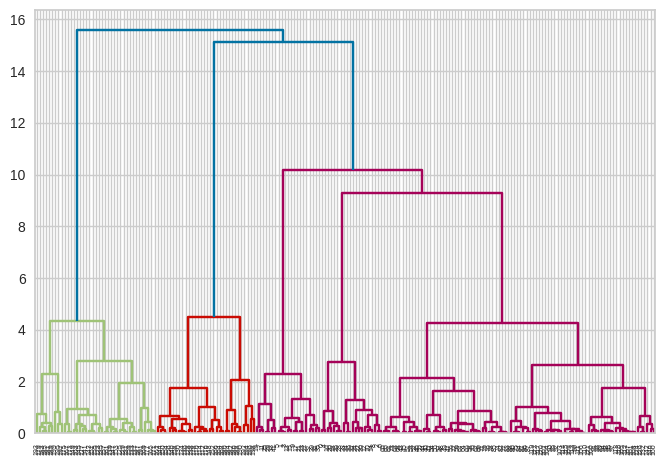

In [ ]:
from scipy.cluster.hierarchy import linkage,dendrogram
link_mat=linkage(scaled_cluster,method='ward')
dendrogram(link_mat)
plt.show()

In [ ]:
#linkages in agglomerative

###### Silhouette Score

##### DBSCAN (Density-Based Spatial Clustering of Applications with Noise)

Definition:
DBSCAN is a density-based clustering algorithm that groups together points that are closely packed (dense regions) and marks points in low-density areas as outliers (noise).
It does not require specifying the number of clusters in advance.

###### DBSCAN Model

In [ ]:
scaled_cluster.head()

,Yearly_Income,Cust_Spend_Score,dbscan_clusters
0,-1.738999,-0.284181,2
1,-1.738999,1.063563,0
2,-1.700830,-1.670433,1
3,-1.700830,1.063563,0
4,-1.662660,-0.399702,2


In [ ]:
from sklearn.cluster import DBSCAN
db_scan=DBSCAN(min_samples=4,eps=0.33)
scaled_cluster['dbscan_clusters']=db_scan.fit_predict(scaled_cluster)

/tmp/ipykernel_999/1822975413.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  scaled_cluster['dbscan_clusters']=db_scan.fit_predict(scaled_cluster)


##### Dimensionality Reduction Technique

Dimensionality Reduction is a technique used in machine learning and data analysis to reduce the number of input variables (features) in a dataset while keeping the most important information.
It helps simplify models, improve performance, and remove redundant or less informative features.

In simple words:
Dimensionality Reduction means reducing the number of features in the data but keeping the most meaningful patterns.

In [ ]:
#here we have

In [ ]:
df=pd.read_csv('/content/attrition.csv')
df.head(2)

,Age,DailyRate,DistanceFromHome,HourlyRate,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition
0,53,124,2,38,7525,23537,2,12,30,2,15,7,6,12,0
1,21,337,7,31,2679,4567,1,13,1,3,1,0,1,0,1


In [ ]:
df.shape

(2233, 15)

In [ ]:
from sklearn.model_selection import train_test_split
x=df.drop(columns=['Attrition'])
y=df['Attrition']
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.25,random_state=100)
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()
xtrian_scaled=pd.DataFrame(ss.fit_transform(xtrain),columns=xtrain.columns)
xtest_scaled=pd.DataFrame(ss.transform(xtest),columns=xtest.columns)

##### PCA (Principal Component Analysis)

Principal Component Analysis (PCA) is a statistical technique used for dimensionality reduction that transforms the original correlated features into a new set of uncorrelated variables called principal components.
These components capture the maximum variance (information) in the data using fewer dimensions.

In simple words:
PCA finds new axes (directions) in the data that explain most of the variation and uses them to represent the data with fewer features.

##### PCA Model

In [ ]:
from sklearn.decomposition import PCA
pca=PCA()
pca_xtrain=pca.fit_transform(xtrian_scaled)
pca_xtest=pca.transform(xtest_scaled)

In [ ]:
pca_xtrain=pd.DataFrame(pca_xtrain,columns=['PC1','PC2','PC3','PC4','PC5','PC6','PC7','PC8','PC9','PC10','PC11','PC12','PC13','PC14'])
pca_xtest=pd.DataFrame(pca_xtest,columns=['PC1','PC2','PC3','PC4','PC5','PC6','PC7','PC8','PC9','PC10','PC11','PC12','PC13','PC14'])

In [ ]:
pca.explained_variance_ratio_

array([0.30291651, 0.11023615, 0.0835254 , 0.072379  , 0.07150437,
       0.07082663, 0.06660603, 0.06453163, 0.05061553, 0.03381823,
       0.03024041, 0.0186498 , 0.01493721, 0.00921311])

In [ ]:
import numpy as np
np.cumsum(pca.explained_variance_ratio_)

array([0.30291651, 0.41315266, 0.49667806, 0.56905705, 0.64056142,
       0.71138805, 0.77799408, 0.84252572, 0.89314125, 0.92695947,
       0.95719988, 0.97584968, 0.99078689, 1.        ])

In [ ]:
#we will use 9 principal components to build the model which predicts attrition and evaluate

##### PCA Model Evaluation

In [ ]:
pca_modal_train_data=pca_xtrain.iloc[:,0:9]
pca_model_test_data=pca_xtest.iloc[:,0:9]

In [ ]:
from sklearn.linear_model import LogisticRegression
lr=LogisticRegression()
lr.fit(pca_modal_train_data,ytrain)
model_predict=lr.predict(pca_model_test_data)


In [ ]:
from sklearn.metrics import classification_report
print(classification_report(model_predict,ytest))

              precision    recall  f1-score   support

           0       0.69      0.70      0.70       320
           1       0.59      0.58      0.58       239

    accuracy                           0.65       559
   macro avg       0.64      0.64      0.64       559
weighted avg       0.65      0.65      0.65       559



##### Association Rule Learning

Association Rule Learning is an unsupervised machine learning technique used to find hidden relationships or patterns between variables in large datasets.
It helps identify how the occurrence of one item is associated with another.

In simple words:
It finds “if–then” relationships in data — for example, “If a customer buys bread, they are likely to buy butter.

##### Apriori Algorithm:

The Apriori Algorithm is a fundamental algorithm used in association rule learning to identify frequent itemsets in large datasets.
It works by using the “Apriori property”, which states that if an itemset is frequent, then all of its subsets must also be frequent.

In simple words:
Apriori helps find which items often appear together and then builds association rules from them.

Example:
Using Apriori to discover that {Milk, Bread} → {Butter} appears frequently in transaction data.

In [ ]:
!pip install mlxtend

In [ ]:
# 1. Sample Transaction Dataset
transactions = [
    ['Milk', 'Bread', 'Eggs'],
    ['Milk', 'Bread'],
    ['Milk', 'Eggs'],
    ['Bread', 'Butter'],
    ['Milk', 'Butter'],
    ['Bread', 'Eggs'],
]

In [ ]:
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

In [ ]:
from warnings import filterwarnings
filterwarnings('ignore')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
#lets covert the transctions to some sort of encoded data
te=TransactionEncoder()
df_transctions=pd.DataFrame(te.fit_transform(transactions),columns=te.columns_)
df_transctions.head()
#lets find the frequent items sets by passing the min support value:0.2
#all the posible 1 items 2 items sets 3 items sets will be calculated automatically
frequent_itemsets=apriori(df_transctions,min_support=0.2,use_colnames=True)
frequent_itemsets.head()

,support,itemsets
0,0.833333,(Bread)
1,0.833333,(Butter)
2,0.416667,(Cookies)
3,0.250000,(Egg)
4,0.250000,(Ketchup)


In [ ]:
#now using qulified item sets we calculate the ruls
association_rules(frequent_itemsets,metric='confidence',min_threshold=0.5)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(Eggs),(Bread),0.500000,0.666667,0.333333,0.666667,1.00,1.0,0.000000,1.000000,0.0,0.400000,0.0,0.583333
1,(Bread),(Eggs),0.666667,0.500000,0.333333,0.500000,1.00,1.0,0.000000,1.000000,0.0,0.400000,0.0,0.583333
2,(Milk),(Bread),0.666667,0.666667,0.333333,0.500000,0.75,1.0,-0.111111,0.666667,-0.5,0.333333,-0.5,0.500000
3,(Bread),(Milk),0.666667,0.666667,0.333333,0.500000,0.75,1.0,-0.111111,0.666667,-0.5,0.333333,-0.5,0.500000
4,(Eggs),(Milk),0.500000,0.666667,0.333333,0.666667,1.00,1.0,0.000000,1.000000,0.0,0.400000,0.0,0.583333
5,(Milk),(Eggs),0.666667,0.500000,0.333333,0.500000,1.00,1.0,0.000000,1.000000,0.0,0.400000,0.0,0.583333


In [ ]:
#here we need to consider the antecedents(A) and consequents(b) and lift value.
#if lift value is greater than 1(here we took 0.5) we say confidently there is a strong relation among that item set

##### Market Basket Analysis:

Market Basket Analysis is an application of association rule learning that studies the co-occurrence of products in customer transactions.
It helps retailers understand which items are frequently bought together and improve product placement, cross-selling, and promotions.

In simple words:
Market Basket Analysis finds products that are often purchased together in the same shopping basket.

In [ ]:
 transactions2= [
    ['Milk', 'Egg', 'Bread', 'Butter'],
    ['Milk', 'Butter', 'Egg', 'Ketchup'],
    ['Bread', 'Butter', 'Ketchup'],
    ['Milk', 'Bread', 'Butter'],
    ['Bread', 'Butter', 'Cookies'],
    ['Milk', 'Bread', 'Butter','Cookies'],
    ['Milk','Cookies'],
    ['Milk', 'Bread', 'Butter'],
    ['Bread', 'Butter', 'Egg', 'Cookies'],
    ['Milk', 'Butter', 'Bread'],
    ['Milk', 'Bread', 'Butter'],
    ['Milk', 'Bread', 'Cookies', 'Ketchup']
]

In [ ]:
trans_dataframe=pd.DataFrame(te.fit_transform(transactions2),columns=te.columns_)
trans_dataframe.head()
#now lets find the frequent items sets
frequent_items=apriori(trans_dataframe,min_support=0.2,use_colnames=True)
frequent_items

,support,itemsets
0,0.833333,(Bread)
1,0.833333,(Butter)
2,0.416667,(Cookies)
3,0.250000,(Egg)
4,0.250000,(Ketchup)
5,0.750000,(Milk)
6,0.750000,"(Butter, Bread)"
7,0.333333,"(Cookies, Bread)"
8,0.583333,"(Milk, Bread)"
9,0.250000,"(Cookies, Butter)"


In [ ]:
association_rules(frequent_items,metric='confidence',min_threshold=1)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(Egg),(Butter),0.25,0.833333,0.25,1.0,1.2,1.0,0.041667,inf,0.222222,0.3,1.0,0.65
1,"(Cookies, Butter)",(Bread),0.25,0.833333,0.25,1.0,1.2,1.0,0.041667,inf,0.222222,0.3,1.0,0.65


##### Recommendation Systems

A Recommendation System is a machine learning application that predicts and suggests items a user may like based on their past behavior, preferences, or similarity to other users or items.
These systems are widely used in e-commerce, streaming platforms, and online services.

In simple words:
Recommendation Systems help users discover new items they’re likely to be interested in — like movies, songs, or products.

##### Collaborative Filtering

Collaborative Filtering is a recommendation technique that makes predictions based on the behavior and preferences of many users.
It assumes that users with similar tastes in the past will have similar preferences in the future.

In simple words:
Collaborative Filtering recommends an item to a user by finding other users or items that are similar.

Two main types:

User-Based Collaborative Filtering – finds users similar to the target user and recommends items they liked.

Item-Based Collaborative Filtering – finds items similar to what the user liked and recommends them.

In [ ]:
# create a new env in anaconda prompt
# than install surprise package in it
# than integrate it with jupyter notebook


#Run these commands in Anaconda Prompt.
create -n recommender_env python=3.10
activate recommender_env
conda install -c conda-forge scikit-surprise
install surprise
conda install ipykernel
python -m ipykernel install --user --name recommender_env --display-name 'recommended_env'

In [2]:
import pandas as pd
from surprise import Dataset, Reader, KNNBasic

In [ ]:
#!pip install surprise

In [5]:
ratings_dict = {
    'userID': ['A', 'A', 'A',  # User A (Missing Item 4)
               'B', 'B', 'B', 'B',
               'C', 'C', 'C', 'C',
               'D', 'D', 'D', 'D'],
    'itemID': ['I1', 'I2', 'I3',
               'I1', 'I2', 'I3', 'I4',
               'I1', 'I2', 'I3', 'I4',
               'I1', 'I2', 'I3', 'I4'],
    'rating': [4, 3, 5,
               5, 5, 4, 3,
               4, 3, 5, 3,
               2, 4, 2, 3]
}
df = pd.DataFrame(ratings_dict)
df.head(2)

,userID,itemID,rating
0,A,I1,4
1,A,I2,3


In [8]:
reader=Reader(rating_scale=(1,5))

#load the data in surprise package format
data=Dataset.load_from_df(df[['userID','itemID','rating']], reader)
trainset=data.build_full_trainset()

#2user-based filtering
#3configuration:use cosine similarity, and user_based=True
sim_options_user={'name':'cosine','user_based':True}

#building model
user_based_model=KNNBasic(sim_options_user)

#model trining
user_based_model.fit(trainset)

#predict the rating which is missing by user  for item 4
prediction=user_based_model.predict(uid='A',iid=4)

prediction.est

Computing the msd similarity matrix...
Done computing similarity matrix.


np.float64(3.6666666666666665)